# Lab 2 - Phần 2.3: Naïve Bayes
**Nội dung:** bài mẫu (Spam email) + Bài tập 1 (Customer Behaviour - GaussianNB) + Bài tập 2 (Mushroom - NB cho dữ liệu phân loại).

**Dữ liệu:** `spam.csv`, `Social_Network_Ads.csv`, `mushrooms.csv`

In [1]:
import sys; sys.path.append(".")
from utils import *
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB, ComplementNB
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, LabelEncoder
from sklearn.metrics import roc_curve, roc_auc_score

## A. Bài làm mẫu - Phân loại email Spam (MultinomialNB)

[Đọc dữ liệu] data\spam.csv
===== Spam =====
Kích thước: 5157 dòng x 2 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
label,object,0,0.0,2
text,object,0,0.0,5157


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,count
label,
ham,4516
spam,641


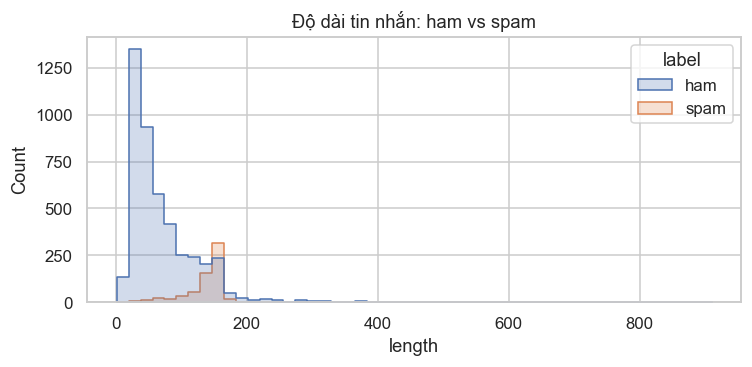

[Đã lưu] figures\s23_spam_length.png


In [2]:
sp = load_table("spam.csv", "*spam*.csv", encoding="latin-1")
sp = sp.iloc[:, :2]; sp.columns = ["label", "text"]
sp = sp.dropna().drop_duplicates()
overview(sp, "Spam")
display(sp["label"].value_counts().to_frame("count"))
sp["length"] = sp["text"].str.len()
plt.figure(figsize=(7, 3.5)); sns.histplot(data=sp, x="length", hue="label", bins=50, element="step", common_norm=False)
plt.title("Độ dài tin nhắn: ham vs spam"); save_fig("s23_spam_length")


===== Spam BoW + MultinomialNB =====
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      1130
        spam       0.94      0.91      0.92       160

    accuracy                           0.98      1290
   macro avg       0.96      0.95      0.96      1290
weighted avg       0.98      0.98      0.98      1290



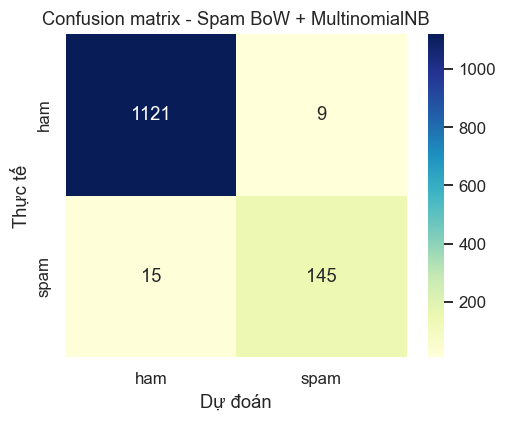

[Đã lưu] figures\cm_spam_bow_multinomialnb.png

===== Spam TFIDF + MultinomialNB =====
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98      1130
        spam       1.00      0.70      0.82       160

    accuracy                           0.96      1290
   macro avg       0.98      0.85      0.90      1290
weighted avg       0.96      0.96      0.96      1290


===== Spam TFIDF + ComplementNB =====
              precision    recall  f1-score   support

         ham       0.99      0.97      0.98      1130
        spam       0.80      0.91      0.85       160

    accuracy                           0.96      1290
   macro avg       0.89      0.94      0.92      1290
weighted avg       0.96      0.96      0.96      1290

Tham số tốt nhất: {'nb__alpha': 0.5, 'vec__ngram_range': (1, 2)} | CV f1_macro = 0.9624

===== Spam NB (tối ưu) =====
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99    

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Spam NB (tối ưu),0.9837,0.9484,0.9188,0.9333,0.9797
Spam BoW + MultinomialNB,0.9814,0.9416,0.9062,0.9236,0.9824
Spam TFIDF + ComplementNB,0.9612,0.8022,0.9125,0.8538,0.9841
Spam TFIDF + MultinomialNB,0.9628,1.0000,0.7000,0.8235,0.9841


In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(sp["text"], sp["label"], test_size=0.25, random_state=RANDOM_STATE, stratify=sp["label"])

# Bag-of-Words + MultinomialNB
bow = Pipeline([("vec", CountVectorizer(stop_words="english")), ("nb", MultinomialNB())]).fit(X_tr, y_tr)
res_spam = [evaluate_model(bow, X_te, y_te, "Spam BoW + MultinomialNB")]

# TF-IDF + MultinomialNB, và ComplementNB
tfidf = Pipeline([("vec", TfidfVectorizer(stop_words="english")), ("nb", MultinomialNB())]).fit(X_tr, y_tr)
res_spam.append(evaluate_model(tfidf, X_te, y_te, "Spam TFIDF + MultinomialNB", plot=False))
comp = Pipeline([("vec", TfidfVectorizer(stop_words="english")), ("nb", ComplementNB())]).fit(X_tr, y_tr)
res_spam.append(evaluate_model(comp, X_te, y_te, "Spam TFIDF + ComplementNB", plot=False))

# Tối ưu làm trơn Laplace (alpha)
gs = GridSearchCV(Pipeline([("vec", CountVectorizer(stop_words="english")), ("nb", MultinomialNB())]),
                  {"nb__alpha": [0.01, 0.1, 0.5, 1.0, 2.0], "vec__ngram_range": [(1, 1), (1, 2)]},
                  cv=5, scoring="f1_macro", n_jobs=-1).fit(X_tr, y_tr)
print("Tham số tốt nhất:", gs.best_params_, "| CV f1_macro =", round(gs.best_score_, 4))
res_spam.append(evaluate_model(gs.best_estimator_, X_te, y_te, "Spam NB (tối ưu)", plot=False))
display(results_table(res_spam))

In [4]:
# Từ đặc trưng nhất của spam / ham (dựa trên log xác suất có điều kiện)
vec, nb = bow.named_steps["vec"], bow.named_steps["nb"]
words = np.array(vec.get_feature_names_out())
classes = list(nb.classes_)
diff = nb.feature_log_prob_[classes.index("spam")] - nb.feature_log_prob_[classes.index("ham")]
top = pd.DataFrame({"Từ đặc trưng SPAM": words[np.argsort(-diff)[:15]], "Từ đặc trưng HAM": words[np.argsort(diff)[:15]]})
display(top)

# Dự đoán tin nhắn mới
tests = ["Congratulations! You won a FREE prize, call now to claim 1000 cash", "Hi, are we still meeting for lunch tomorrow?"]
for t, p, pr in zip(tests, bow.predict(tests), bow.predict_proba(tests).max(axis=1)):
    print(f"[{p} | {pr:.2f}] {t}")

,Từ đặc trưng SPAM,Từ đặc trưng HAM
0,claim,gt
1,prize,lt
2,150p,lor
3,tone,da
4,guaranteed,ã¼
5,500,oh
6,www,later
7,18,really
8,1000,doing
9,cs,ask


[spam | 1.00] Congratulations! You won a FREE prize, call now to claim 1000 cash
[ham | 1.00] Hi, are we still meeting for lunch tomorrow?


## B. Bài tập 1 - Customer Behaviour (GaussianNB)
Dự đoán khách hàng có mua sản phẩm sau khi xem quảng cáo trên mạng xã hội hay không, từ tuổi và mức lương ước tính.

In [5]:
ad = load_table("Social_Network_Ads.csv", "*social*ads*.csv", "*customer*behav*.csv", "*ads*.csv")
overview(ad, "Social Network Ads")
tgt = guess_column(ad, ["Purchased", "Buy", "Target"])
ad = ad.drop(columns=[c for c in ad.columns if c.lower().replace(" ", "") in ("userid", "id")], errors="ignore")
if "Gender" in ad.columns:
    ad["Gender"] = ad["Gender"].map({"Male": 0, "Female": 1})
print("Đặc trưng:", [c for c in ad.columns if c != tgt])

[Đọc dữ liệu] data\Social_Network_Ads.csv
===== Social Network Ads =====
Kích thước: 400 dòng x 3 cột
Số dòng trùng lặp: 33


,dtype,missing,missing_%,n_unique
Age,int64,0,0.0,43
EstimatedSalary,int64,0,0.0,117
Purchased,int64,0,0.0,2


,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


Đặc trưng: ['Age', 'EstimatedSalary']


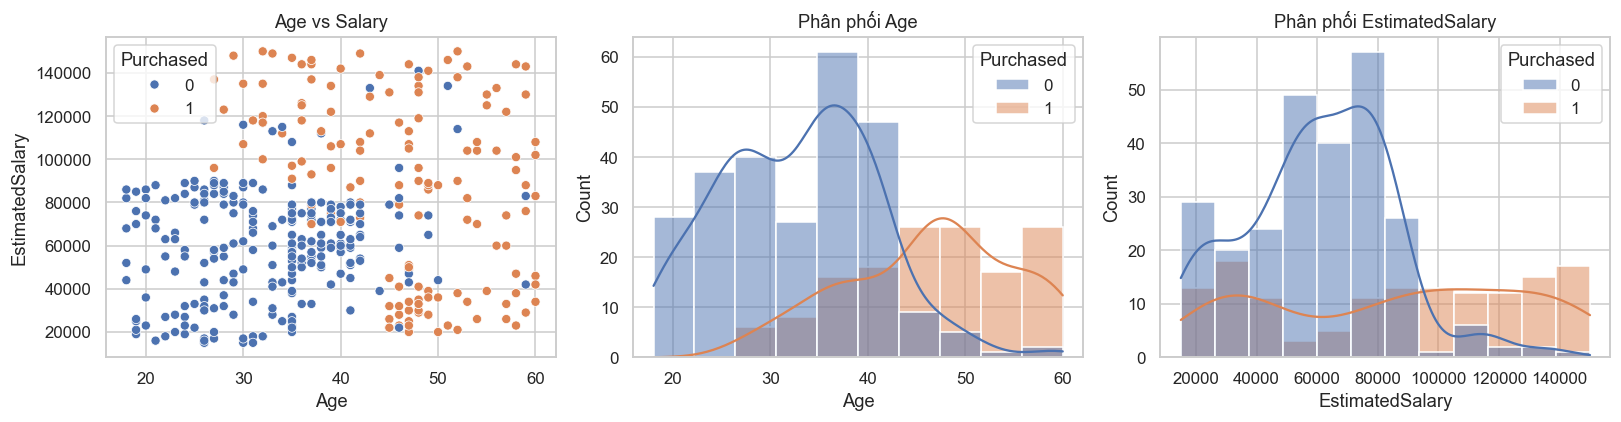

[Đã lưu] figures\s23_ads_eda.png


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=ad, x="Age", y="EstimatedSalary", hue=tgt, ax=axs[0]); axs[0].set_title("Age vs Salary")
sns.histplot(data=ad, x="Age", hue=tgt, kde=True, ax=axs[1]); axs[1].set_title("Phân phối Age")
sns.histplot(data=ad, x="EstimatedSalary", hue=tgt, kde=True, ax=axs[2]); axs[2].set_title("Phân phối EstimatedSalary")
save_fig("s23_ads_eda")


===== Ads GaussianNB =====
              precision    recall  f1-score   support

   Không mua       0.88      0.94      0.91        64
         Mua       0.88      0.78      0.82        36

    accuracy                           0.88       100
   macro avg       0.88      0.86      0.87       100
weighted avg       0.88      0.88      0.88       100



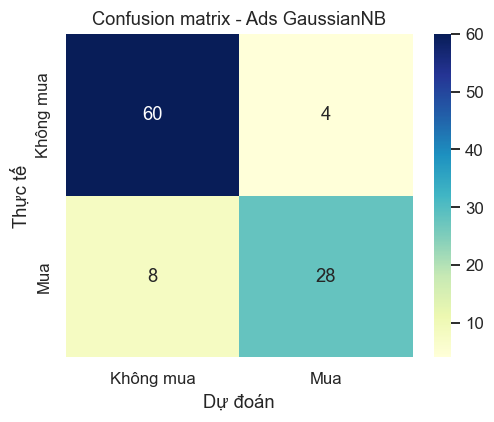

[Đã lưu] figures\cm_ads_gaussiannb.png

===== Ads GaussianNB + scale =====
              precision    recall  f1-score   support

   Không mua       0.88      0.92      0.90        64
         Mua       0.85      0.78      0.81        36

    accuracy                           0.87       100
   macro avg       0.86      0.85      0.86       100
weighted avg       0.87      0.87      0.87       100

CV accuracy (5-fold): [0.888 0.925 0.85  0.862 0.875] | TB = 0.88


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Ads GaussianNB,0.88,0.8750,0.7778,0.8235,0.9466
Ads GaussianNB + scale,0.87,0.8485,0.7778,0.8116,0.9470


In [7]:
y = ad[tgt]; X = ad.drop(columns=tgt)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

# GaussianNB không bắt buộc chuẩn hóa, nhưng so sánh có/không chuẩn hóa để chứng minh
nb_raw = GaussianNB().fit(X_tr, y_tr)
nb_scaled = Pipeline([("sc", StandardScaler()), ("nb", GaussianNB())]).fit(X_tr, y_tr)
res_ad = [evaluate_model(nb_raw, X_te, y_te, "Ads GaussianNB", ["Không mua", "Mua"]),
          evaluate_model(nb_scaled, X_te, y_te, "Ads GaussianNB + scale", ["Không mua", "Mua"], plot=False)]
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("CV accuracy (5-fold):", cross_val_score(GaussianNB(), X, y, cv=skf).round(3), "| TB =", cross_val_score(GaussianNB(), X, y, cv=skf).mean().round(4))
display(results_table(res_ad))

Prior P(class): {np.int64(0): np.float64(0.643), np.int64(1): np.float64(0.357)}


,Age,EstimatedSalary
mean | class 0,32.22,60124.35
mean | class 1,46.01,90345.79


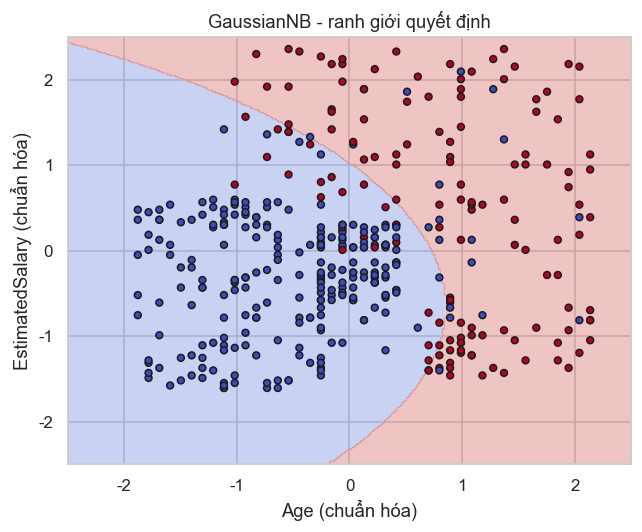

[Đã lưu] figures\s23_ads_decision_boundary.png


In [8]:
# Tham số học được: trung bình và phương sai của từng đặc trưng theo lớp
print("Prior P(class):", dict(zip(nb_raw.classes_, nb_raw.class_prior_.round(3))))
display(pd.DataFrame(nb_raw.theta_, index=[f"mean | class {c}" for c in nb_raw.classes_], columns=X.columns).round(2))

# Ranh giới quyết định trên (Age, EstimatedSalary)
Xb = X[["Age", "EstimatedSalary"]]
sc = StandardScaler().fit(Xb); nb2 = GaussianNB().fit(sc.transform(Xb), y)
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
Z = nb2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(6, 5)); plt.contourf(xx, yy, Z, alpha=.3, cmap="coolwarm")
plt.scatter(*sc.transform(Xb).T, c=y, cmap="coolwarm", edgecolor="k", s=20)
plt.xlabel("Age (chuẩn hóa)"); plt.ylabel("EstimatedSalary (chuẩn hóa)"); plt.title("GaussianNB - ranh giới quyết định")
save_fig("s23_ads_decision_boundary")

## C. Bài tập 2 - Mushroom (Naïve Bayes cho dữ liệu phân loại)
Dự đoán nấm ăn được (`e`) hay có độc (`p`). Toàn bộ thuộc tính là dạng phân loại.

In [9]:
mu = load_table("mushrooms.csv", "mushroom*.csv", "*mushroom*.csv")
overview(mu, "Mushroom")
tgt = guess_column(mu, ["class", "Class", "poisonous"])
display(mu[tgt].value_counts().to_frame("count"))
# Thuộc tính có giá trị '?' là thiếu (ví dụ stalk-root)
q = (mu == "?").sum(); print("Giá trị '?':", q[q > 0].to_dict())

[Đọc dữ liệu] data\mushrooms.csv
===== Mushroom =====
Kích thước: 8124 dòng x 23 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
class,object,0,0.0,2
cap-shape,object,0,0.0,6
cap-surface,object,0,0.0,4
cap-color,object,0,0.0,10
bruises,object,0,0.0,2
odor,object,0,0.0,9
gill-attachment,object,0,0.0,2
gill-spacing,object,0,0.0,2
gill-size,object,0,0.0,2
gill-color,object,0,0.0,12


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


,count
class,
e,4208
p,3916


Giá trị '?': {'stalk-root': 2480}


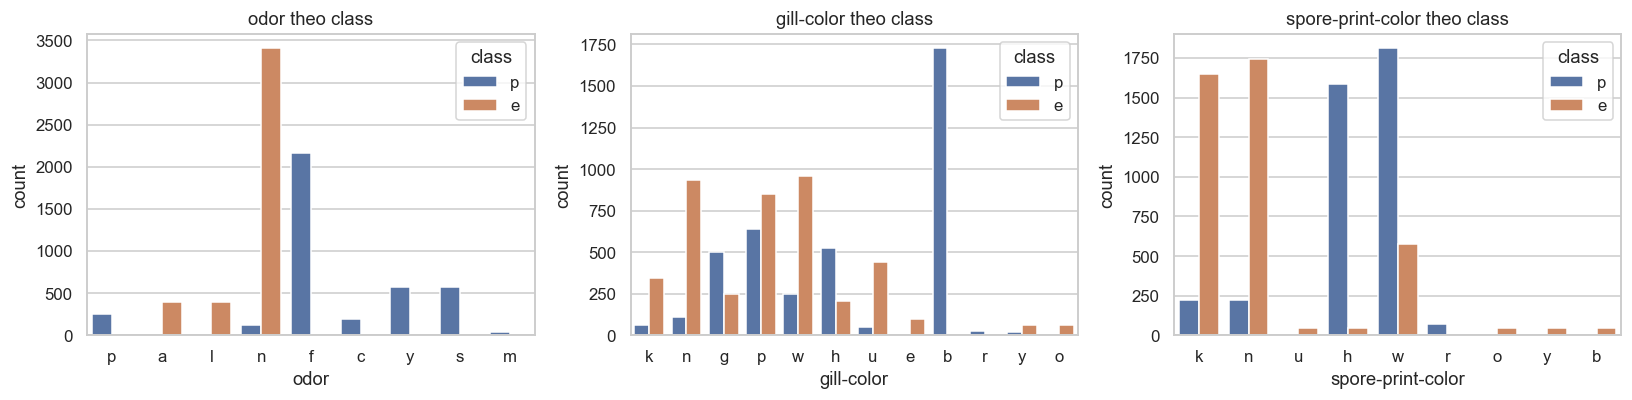

[Đã lưu] figures\s23_mushroom_eda.png


In [10]:
# Độ phân biệt của một số thuộc tính
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axs, [guess_column(mu, ["odor"], False), guess_column(mu, ["gill-color", "gill_color"], False), guess_column(mu, ["spore-print-color", "spore_print_color"], False)]):
    if c: sns.countplot(data=mu, x=c, hue=tgt, ax=ax); ax.set_title(f"{c} theo class")
save_fig("s23_mushroom_eda")


===== Mushroom CategoricalNB =====
              precision    recall  f1-score   support

 Ăn được (e)       0.92      0.99      0.96      1052
     Độc (p)       0.99      0.91      0.95       979

    accuracy                           0.95      2031
   macro avg       0.96      0.95      0.95      2031
weighted avg       0.96      0.95      0.95      2031



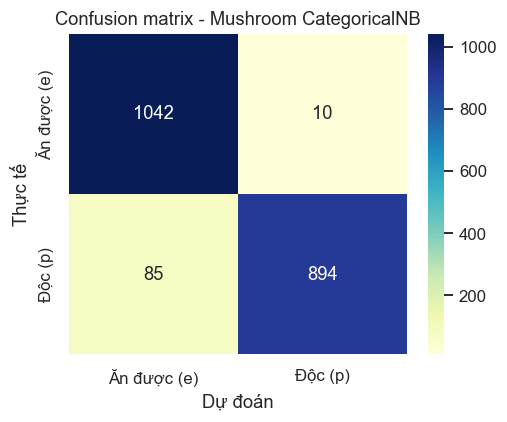

[Đã lưu] figures\cm_mushroom_categoricalnb.png

===== Mushroom BernoulliNB =====
              precision    recall  f1-score   support

 Ăn được (e)       0.91      0.99      0.94      1052
     Độc (p)       0.98      0.89      0.93       979

    accuracy                           0.94      2031
   macro avg       0.94      0.94      0.94      2031
weighted avg       0.94      0.94      0.94      2031



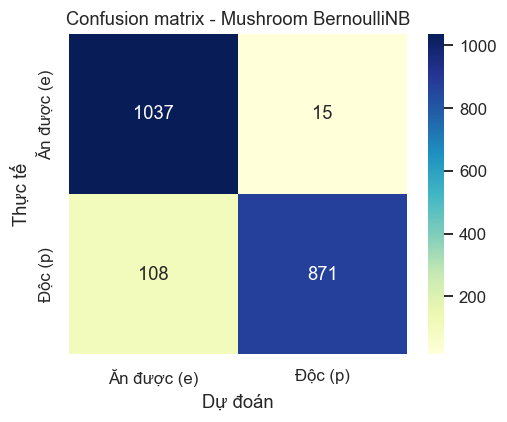

[Đã lưu] figures\cm_mushroom_bernoullinb.png

===== Mushroom MultinomialNB =====
              precision    recall  f1-score   support

 Ăn được (e)       0.92      0.99      0.96      1052
     Độc (p)       0.99      0.91      0.95       979

    accuracy                           0.95      2031
   macro avg       0.96      0.95      0.95      2031
weighted avg       0.96      0.95      0.95      2031



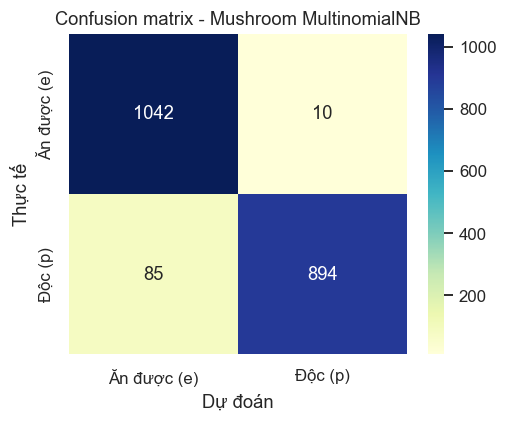

[Đã lưu] figures\cm_mushroom_multinomialnb.png


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Mushroom CategoricalNB,0.9532,0.9889,0.9132,0.9495,0.9978
Mushroom MultinomialNB,0.9532,0.9889,0.9132,0.9495,0.9978
Mushroom BernoulliNB,0.9394,0.9831,0.8897,0.9340,0.9961


In [11]:
y = mu[tgt]; X = mu.drop(columns=tgt)
X = X.replace("?", np.nan)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
cls_names = ["Ăn được (e)", "Độc (p)"]

from sklearn.impute import SimpleImputer
# 1) CategoricalNB: mã hóa thứ tự, mỗi thuộc tính là một phân phối rời rạc riêng
#    (CategoricalNB cần mã >= 0 nên kẹp giá trị 'chưa gặp' -1 về 0)
from sklearn.preprocessing import FunctionTransformer
cat_nb = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                   ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                   ("clip", FunctionTransformer(lambda a: np.clip(a, 0, None))),
                   ("nb", CategoricalNB(alpha=1.0))]).fit(X_tr, y_tr)
# 2) BernoulliNB và 3) MultinomialNB trên One-Hot
oh_steps = lambda: [("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
bern = Pipeline(oh_steps() + [("nb", BernoulliNB())]).fit(X_tr, y_tr)
multi = Pipeline(oh_steps() + [("nb", MultinomialNB())]).fit(X_tr, y_tr)

res_mu = [evaluate_model(cat_nb, X_te, y_te, "Mushroom CategoricalNB", cls_names),
          evaluate_model(bern, X_te, y_te, "Mushroom BernoulliNB", cls_names),
          evaluate_model(multi, X_te, y_te, "Mushroom MultinomialNB", cls_names)]
tab_mu = results_table(res_mu); display(tab_mu)

**Lưu ý khi đánh giá:** với nấm độc, lỗi nghiêm trọng nhất là *dự đoán "ăn được" cho nấm độc* (False Negative của lớp `p`). Hãy quan sát **recall của lớp `p`**, không chỉ accuracy.

In [12]:
# Số nấm độc bị dự đoán nhầm là ăn được ở mỗi mô hình
from sklearn.metrics import confusion_matrix
for n, m in [("CategoricalNB", cat_nb), ("BernoulliNB", bern), ("MultinomialNB", multi)]:
    tn, fp, fn, tp = confusion_matrix(y_te, m.predict(X_te), labels=["e", "p"]).ravel()
    print(f"{n:14s}: nấm độc bị đoán nhầm 'ăn được' = {fn} / {fn + tp} | nấm ăn được bị đoán nhầm 'độc' = {fp} / {fp + tn}")

CategoricalNB : nấm độc bị đoán nhầm 'ăn được' = 85 / 979 | nấm ăn được bị đoán nhầm 'độc' = 10 / 1052
BernoulliNB   : nấm độc bị đoán nhầm 'ăn được' = 108 / 979 | nấm ăn được bị đoán nhầm 'độc' = 15 / 1052
MultinomialNB : nấm độc bị đoán nhầm 'ăn được' = 85 / 979 | nấm ăn được bị đoán nhầm 'độc' = 10 / 1052


In [13]:
# Tối ưu alpha (Laplace smoothing) cho CategoricalNB bằng CV
gs = GridSearchCV(cat_nb, {"nb__alpha": [0.01, 0.1, 0.5, 1, 2, 5]}, cv=5, scoring="recall_macro", n_jobs=-1).fit(X_tr, y_tr)
print("alpha tốt nhất:", gs.best_params_, "| CV =", round(gs.best_score_, 4))

# Thuộc tính ảnh hưởng nhất (mô hình One-Hot BernoulliNB): chênh lệch log-likelihood giữa 2 lớp
names = bern.named_steps["oh"].get_feature_names_out(X.columns)
fl = bern.named_steps["nb"].feature_log_prob_
d = pd.Series(fl[list(bern.classes_).index("p")] - fl[list(bern.classes_).index("e")], index=names)
display(pd.DataFrame({"Chỉ báo nấm ĐỘC (top)": d.sort_values(ascending=False).head(10).index,
                      "Chỉ báo nấm ĂN ĐƯỢC (top)": d.sort_values().head(10).index}))

alpha tốt nhất: {'nb__alpha': 0.01} | CV = 0.99


,Chỉ báo nấm ĐỘC (top),Chỉ báo nấm ĂN ĐƯỢC (top)
0,odor_f,stalk-color-below-ring_g
1,gill-color_b,stalk-color-above-ring_g
2,ring-type_l,population_n
3,odor_y,odor_l
4,odor_s,odor_a
5,stalk-color-above-ring_b,population_a
6,stalk-color-below-ring_b,stalk-color-above-ring_o
7,odor_p,stalk-color-below-ring_o
8,odor_c,habitat_w
9,spore-print-color_r,stalk-root_r


## D. Tổng hợp

In [14]:
final = results_table(res_spam[:1] + res_ad[:1] + res_mu)
display(final); final.to_csv(OUT_DIR / "s23_summary.csv")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Mushroom CategoricalNB,0.9532,0.9889,0.9132,0.9495,0.9978
Mushroom MultinomialNB,0.9532,0.9889,0.9132,0.9495,0.9978
Mushroom BernoulliNB,0.9394,0.9831,0.8897,0.9340,0.9961
Spam BoW + MultinomialNB,0.9814,0.9416,0.9062,0.9236,0.9824
Ads GaussianNB,0.8800,0.8750,0.7778,0.8235,0.9466
